# Домашнее задание: Кластеризация текстов

Сеть супермаркетов «Перекрёсток» собирает отзывы от клиентов по разным каналам: мобильное приложение, сайт, чековые анкеты. Отзывы включают как положительные оценки, так и жалобы — на персонал, доставку, свежесть товаров, наличие и т.д.

**Бизнес сталкивается с проблемой**:

* Отзывов слишком много, они разнообразны по формулировкам.
* Ручная обработка отзывов — долгая и неэффективная.
* Нельзя быстро понять, о чём говорят клиенты, какие темы повторяются.

**Цель бизнеса**:

* Автоматически группировать отзывы по смыслу, чтобы:
* обнаруживать повторяющиеся проблемы (например, "не тот товар", "просрочка"),
* оценивать работу конкретных магазинов и доставок,
* поддерживать продуктовые и операционные улучшения на основе обратной связи.



In [ ]:
!pip freeze > start_env.txt

# Читаем данные

Скачаем данные по отзывам на продукты. Предобработаем их и отфильтруем небольшое количество, чтобы потрогать руками различные алгоритмы, рассмотренные на лекции.

Для упрощения анализа кластеров и возможности здраво оценить, насколько результаты приемлемы, разделим данные на две явно разделенные по смыслу (во всяком случае, в среднем) группы: отзывы с максимальной оценкой и отзывы с минимальной оценкой.

In [1]:
# помогает с ошибкой чтения датасета с HF
!pip install fsspec==2023.6.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.8/163.8 kB 1.7 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2026.2.0
    Uninstalling fsspec-2026.2.0:
      Successfully uninstalled fsspec-2026.2.0


In [2]:
from datasets import load_dataset

# Загружаем train-часть датасета
dataset = load_dataset("lapki/perekrestok-reviews", split="train")
print(dataset)

Using the latest cached version of the dataset since lapki/perekrestok-reviews couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'default' at /home/vampire/.cache/huggingface/datasets/lapki___perekrestok-reviews/default/0.0.0/6579085ad399e03b9f39273a57a79affa299b9c6 (last modified on Sat Apr 18 15:21:05 2026).


Dataset({
    features: ['product_id', 'product_name', 'product_category', 'product_price', 'review_id', 'review_author', 'review_text', 'rating'],
    num_rows: 642682
})


In [3]:
from datasets import load_dataset
import pandas as pd

N = 10000
df = dataset.to_pandas()
df = df[["review_id", "product_category", "product_name", "review_text", "rating"]]
df = df.sort_values(by="review_id").head(N)
df.head(2)


,review_id,product_category,product_name,review_text,rating
128218,1493,Для мам и детей,Сок Сады Придонья Яблоко зеленое 125мл,Самые лучшие соки. Всегда беру детям только их...,5.0
426797,1496,Сладости,Пастила Белевская Пастильная Мануфактура Класс...,"Вкуснее, чем у известных конкурентов.",5.0


In [4]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Применяем очистку
df["clean_text"] = df["review_text"].apply(clean_text)
df.head(2)

,review_id,product_category,product_name,review_text,rating,clean_text
128218,1493,Для мам и детей,Сок Сады Придонья Яблоко зеленое 125мл,Самые лучшие соки. Всегда беру детям только их...,5.0,самые лучшие соки. всегда беру детям только их...
426797,1496,Сладости,Пастила Белевская Пастильная Мануфактура Класс...,"Вкуснее, чем у известных конкурентов.",5.0,"вкуснее, чем у известных конкурентов."


In [5]:
neg = df[df["rating"] == 1.0].sort_values(by="review_id")[:500]
pos = df[df["rating"] == 5.0].sort_values(by="review_id")[:500]
cut_df = pd.concat([neg, pos]).reset_index(drop=True)
cut_df["rating"].value_counts()

rating
1.0    500
5.0    500
Name: count, dtype: int64

In [6]:
cut_df

,review_id,product_category,product_name,review_text,rating,clean_text
0,3972,"Чай, кофе, сахар",Сахар песок белый 1кг,запекала сахар вместе с дыней. дыня совсем не ...,1.0,запекала сахар вместе с дыней. дыня совсем не ...
1,4462,"Чай, кофе, сахар",Кофе молотый Julius Meinl Prasident 250г,Почти без запаха.,1.0,почти без запаха.
2,4836,Замороженные продукты,Вареники От Ильиной с творогом 450г,Не понравились. Начинки мало. К тому же в проц...,1.0,не понравились. начинки мало. к тому же в проц...
3,4905,"Овощи, фрукты, ягоды",Капуста ФЭГ квашеная с морковью 300г,Невозможно есть! Очень невкусно,1.0,невозможно есть! очень невкусно
4,4942,"Овощи, фрукты, ягоды",Капуста ФЭГ квашеная с морковью 300г,"недоквашенная она какая-то, много воды",1.0,"недоквашенная она какая-то, много воды"
...,...,...,...,...,...,...
995,3961,Для мам и детей,Биолакт Тема 3.4% 200мл,"Берем такой и с сахаром, мешаем 50 на 50 и пол...",5.0,"берем такой и с сахаром, мешаем 50 на 50 и пол..."
996,3964,"Овощи, фрукты, ягоды",Огурцы Люкс 450г упаковка,"По вкусу похожи на луховицкие, такие же сладен...",5.0,"по вкусу похожи на луховицкие, такие же сладен..."
997,3965,"Овощи, фрукты, ягоды",Лук репчатый красный,Прекрасный лук для салатов и бургеров. Лежит в...,5.0,прекрасный лук для салатов и бургеров. лежит в...
998,3967,Бытовая химия и гигиена,Средство чистящее Domestos Лимонная свежесть г...,"Хорошее средство для мытья, хорошо очищает под...",5.0,"хорошее средство для мытья, хорошо очищает под..."


# Алгоритмы визуализации - 5 баллов

Реализуйте функции для сжатия эмбеддингов до двумерного пространства с помощью подходов t-SNE и UMAP. Каждая функция должна строить изображения поданных на вход эмбеддингов в пространстве, а также учитывать, какое расстояние между эмбеддингами мы считаем (евклидово или косинусное).

Протестируйте их на небольшом семпле.

In [7]:
from sklearn.manifold import TSNE
import numpy as np
import umap
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Можно реализовать через одну функцию, но для тестирования разных сетапов было удобно делать две отдельно

# Визуализация через t-SNE
def plot_embeddings(embeds, title, metric="euclidean", perplexity = 5, ):
    # ---- Ваш код здесь ----
    if isinstance(embeds, torch.Tensor):
        embeds = embeds.numpy()
    tsne = TSNE(n_components=2, random_state=42, perplexity=perplexity, n_iter_without_progress=1000, metric=metric)
    data_2d = tsne.fit_transform(embeds)
    # ---- Конец кода ----
    df = pd.DataFrame({
        'x': data_2d[:, 0],
        'y': data_2d[:, 1],
       #'class': labels.astype(int)
    })
    plt.figure(figsize=(10, 8))
    sns.scatterplot(
        data=df, 
        x='x', 
        y='y', 
        #hue='class',
        palette='tab10',
        alpha=0.6,
        s=50
    )
    plt.title(title)
    plt.xlabel('t-SNE 1')
    plt.ylabel('t-SNE 2')
    plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


# Визуализация через UMAP
def plot_embeddings_umap(embeds, title, metric="euclidean"):
    if isinstance(embeds, torch.Tensor):
        embeds = embeds.numpy()
    mapp = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
    data_2d = mapp.fit_transform(embeds)
    df = pd.DataFrame({
        'x': data_2d[:, 0],
        'y': data_2d[:, 1],
       #'class': labels.astype(int)
    })
    plt.figure(figsize=(10, 8))
    sns.scatterplot(
        data=df, 
        x='x', 
        y='y', 
        #hue='class',
        palette='tab10',
        alpha=0.6,
        s=50
    )
    plt.title(title)
    plt.xlabel('UMAP 1')
    plt.ylabel('UMAP 2')
    plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    # ---- Ваш код здесь ----
    print("строим umap")
    # ---- Конец кода ----


    plt.show()

/tmp/ipykernel_511/1274015680.py:24: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
/tmp/ipykernel_511/1274015680.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')


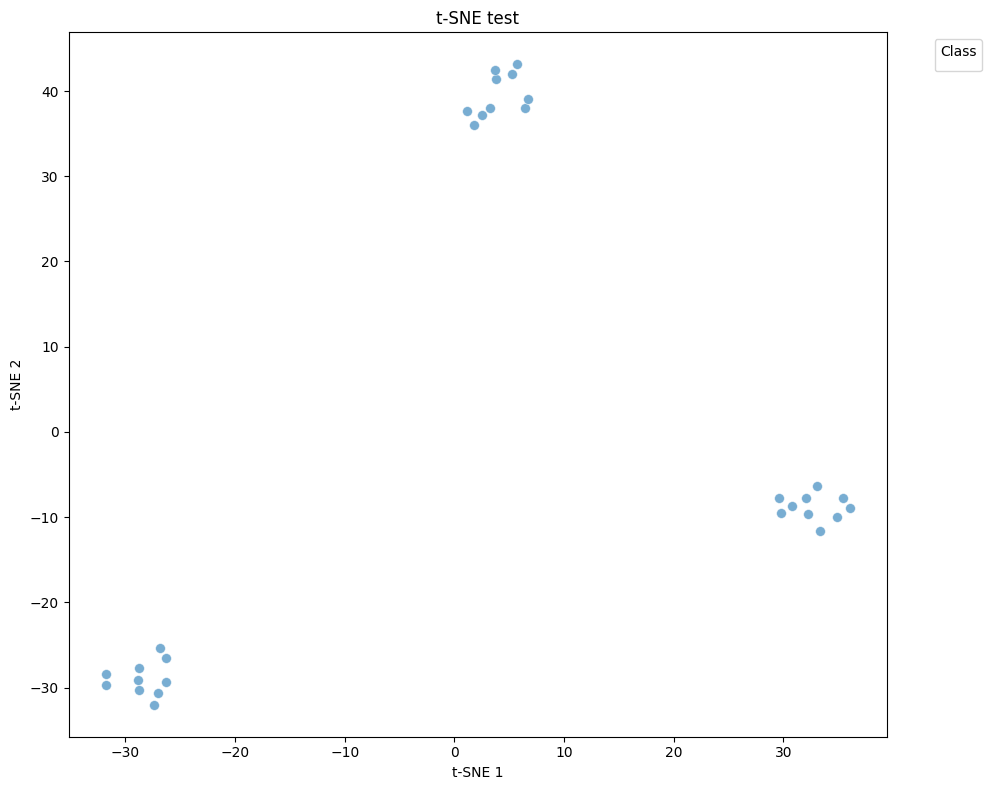

/mnt/f/hw3/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


строим umap


/tmp/ipykernel_511/1274015680.py:53: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
/tmp/ipykernel_511/1274015680.py:65: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')


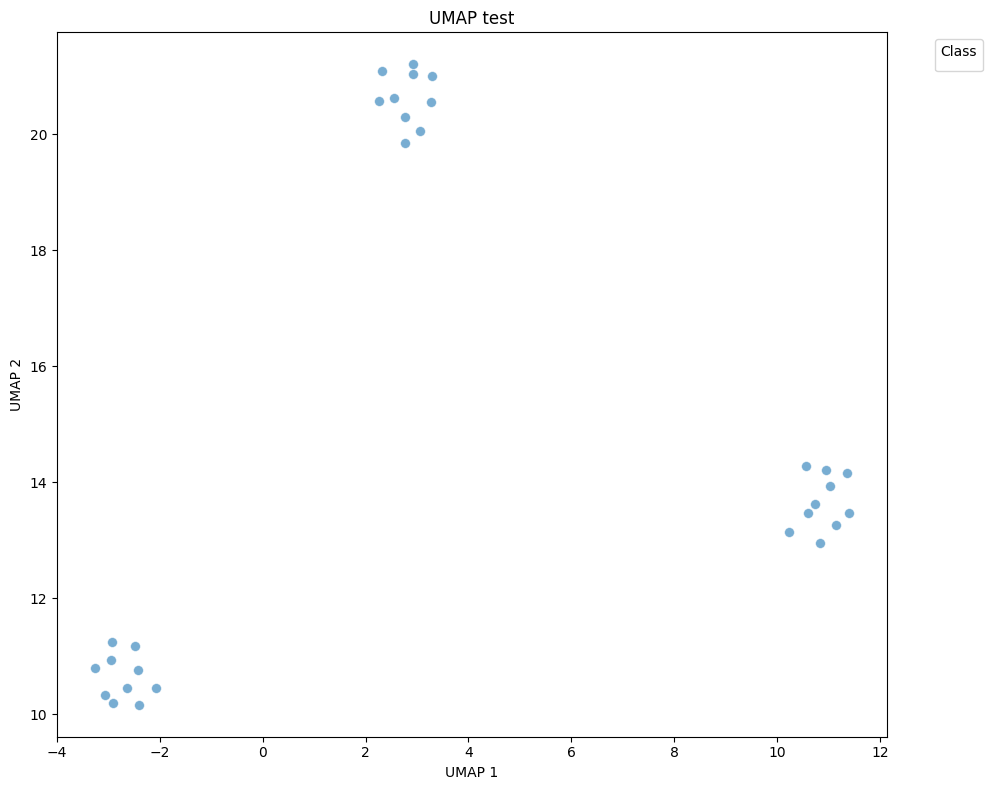

In [8]:
embs = np.concatenate([np.random.rand(10, 3), np.random.rand(10, 3) + 2, np.random.rand(10, 3) - 1], axis=0)
plot_embeddings(embs, "t-SNE test", metric="euclidean")
plot_embeddings_umap(embs, "UMAP test", metric="euclidean")


# Зависимость кластеров от эмбеддера - 5 баллов

В данной части предлагается оценить, насколько эмбеддер на качество кластеризации может влиять:
а) эмбеддер
б) выбранная метрика расстояния

Возьмите следующие две модели:
1) "ai-forever/FRIDA" -- хороший качественный эмбеддер
2) "cointegrated/rubert-tiny2" -- достаточно слабый по современным меркам эмбеддер

Реализуйте подгрузку этой модели через класс SentenceTransformer и постройте визуализацию кластеров
а) через функцию с UMAP и через функцию с t-SNE
б) и для каждого варианта -- визуализацию с евклидовым расстоянием и с косинусным расстоянием
в) и для каждого варианта -- с эмбеддером FRIDA и с эмбеддером rubert-tiny2

Итого должно получиться 8 графиков. Сделайте выводы, какой эмбеддер визуально разграничивает данные лучше.

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

(1000, 1536)


/tmp/ipykernel_511/1274015680.py:24: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
/tmp/ipykernel_511/1274015680.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')


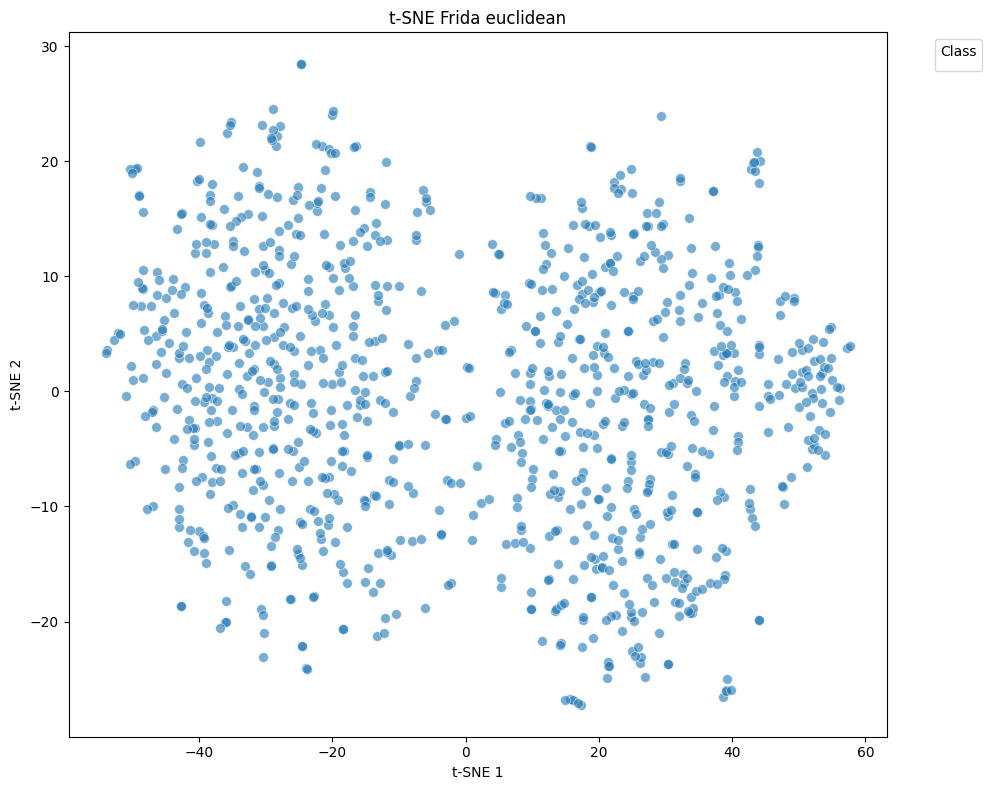

/mnt/f/hw3/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


строим umap


/tmp/ipykernel_511/1274015680.py:53: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
/tmp/ipykernel_511/1274015680.py:65: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')


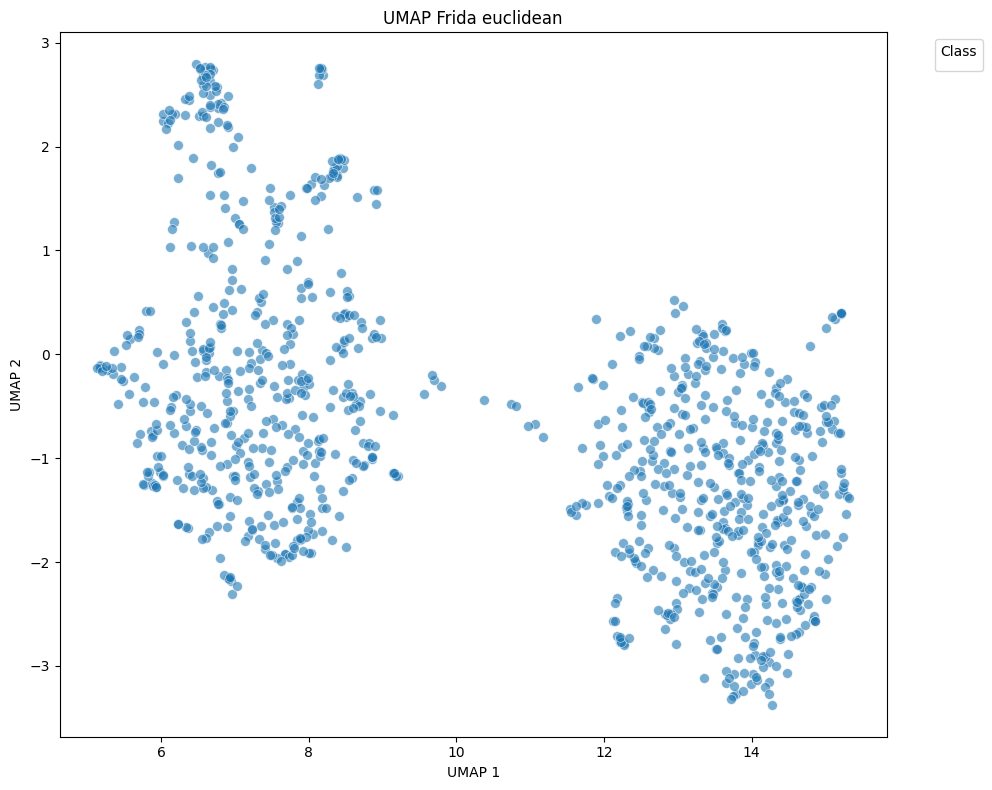

/tmp/ipykernel_511/1274015680.py:24: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
/tmp/ipykernel_511/1274015680.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')


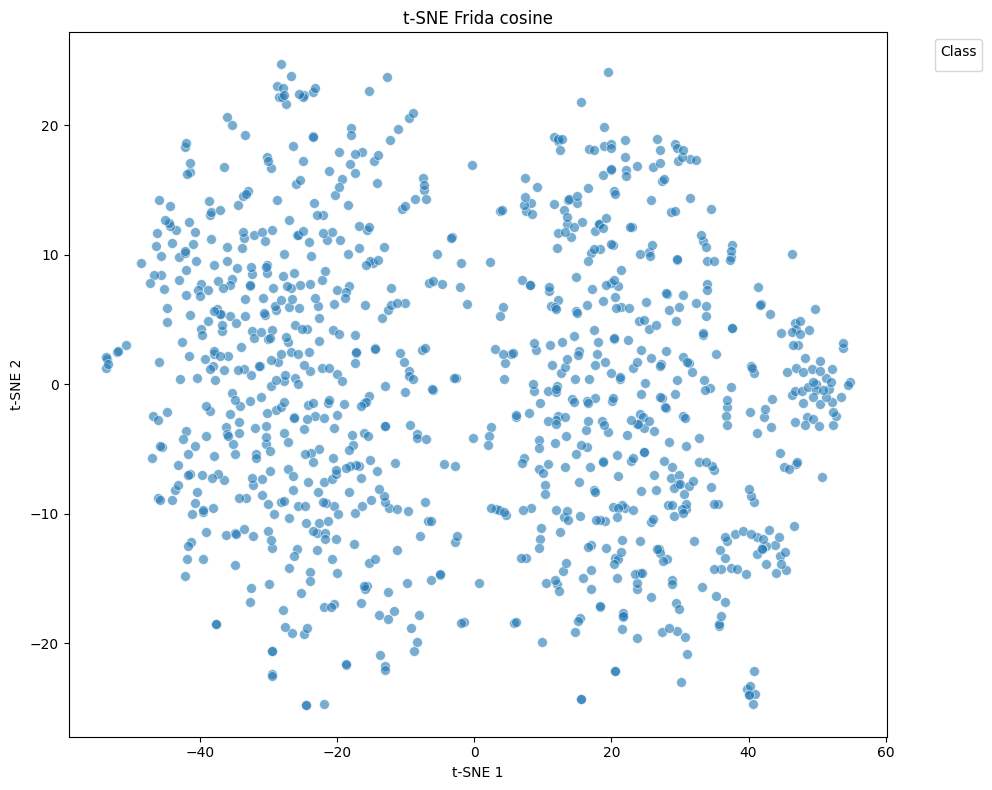

/mnt/f/hw3/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


строим umap


/tmp/ipykernel_511/1274015680.py:53: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
/tmp/ipykernel_511/1274015680.py:65: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')


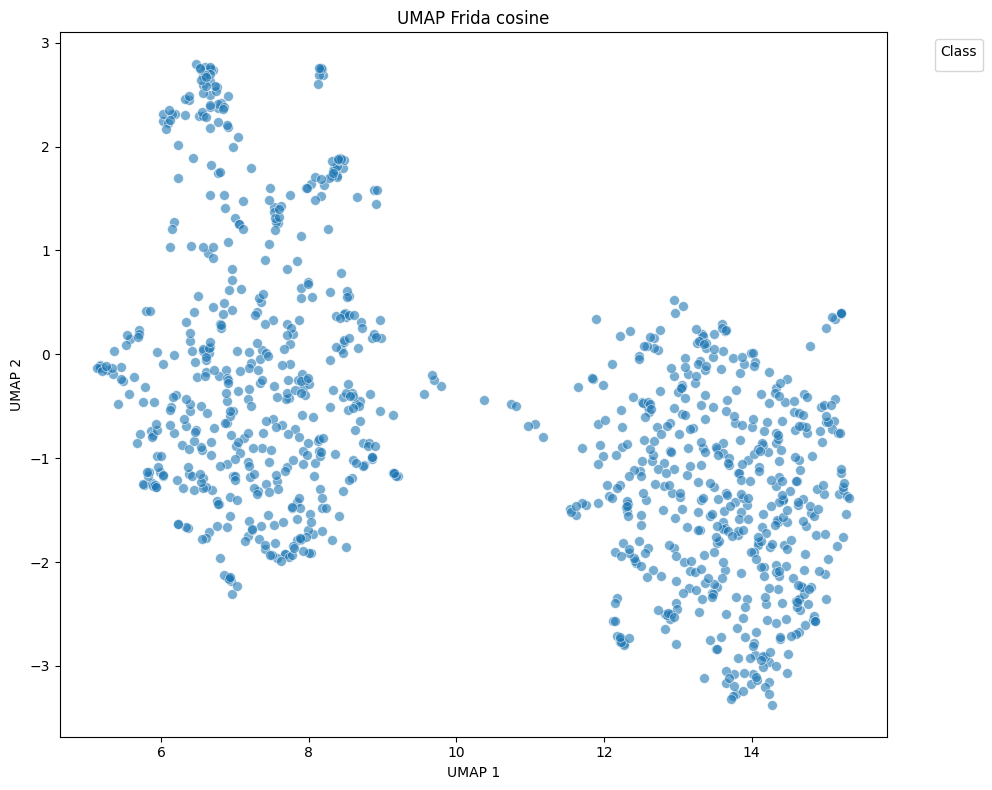

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


(1000, 312)


/tmp/ipykernel_511/1274015680.py:24: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
/tmp/ipykernel_511/1274015680.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')


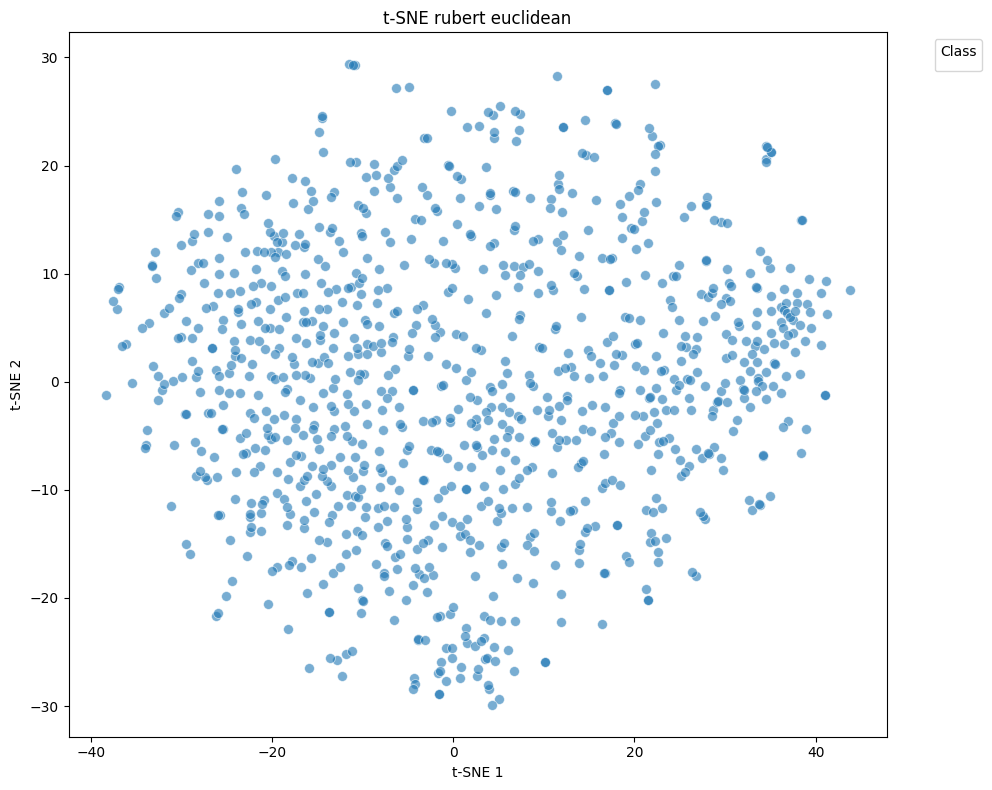

/mnt/f/hw3/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_511/1274015680.py:53: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


строим umap


/tmp/ipykernel_511/1274015680.py:65: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')


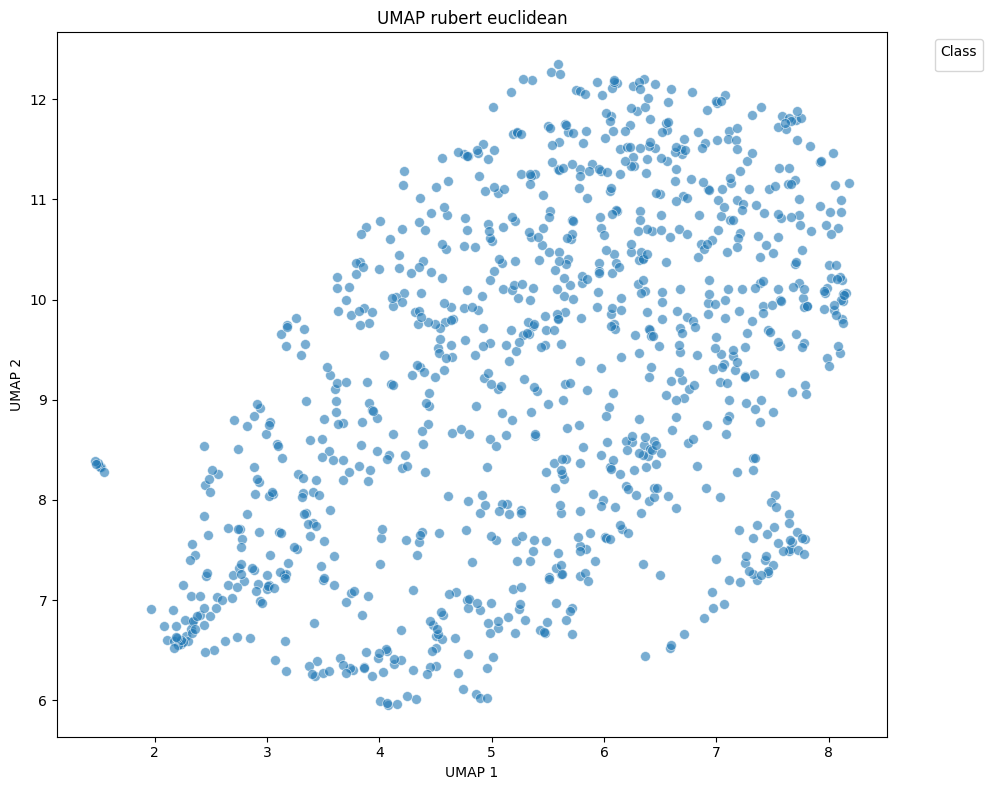

/tmp/ipykernel_511/1274015680.py:24: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
/tmp/ipykernel_511/1274015680.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')


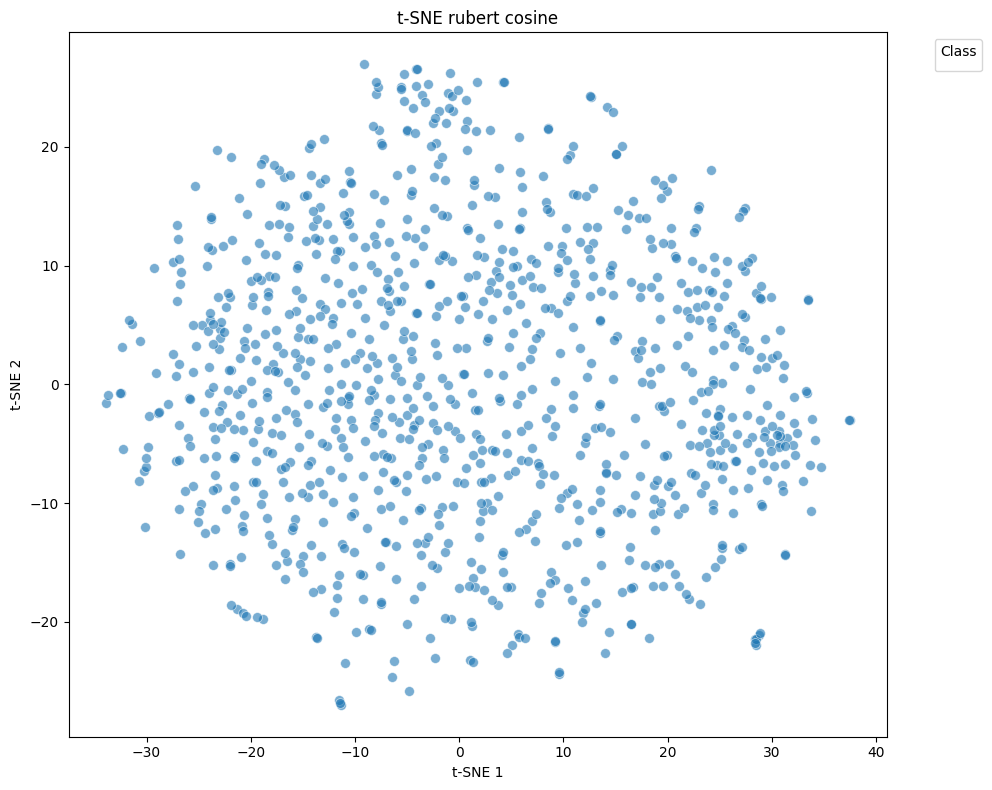

/mnt/f/hw3/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


строим umap


/tmp/ipykernel_511/1274015680.py:53: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
/tmp/ipykernel_511/1274015680.py:65: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')


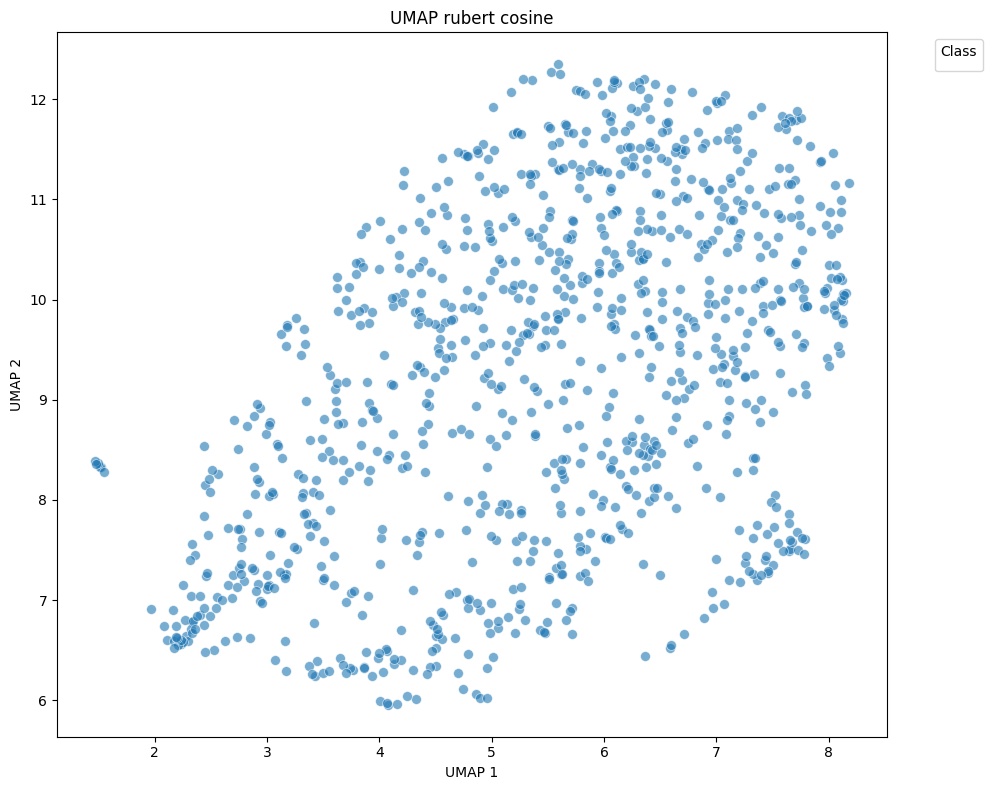

In [9]:
from sentence_transformers import SentenceTransformer

model_name = "ai-forever/FRIDA"
frida_model = SentenceTransformer(model_name)
frida_embeds = frida_model.encode(cut_df['clean_text'].tolist())
print(frida_embeds.shape)
# ---- Ваш код здесь ----
plot_embeddings(frida_embeds, "t-SNE Frida euclidean", metric="euclidean", perplexity=30, )
plot_embeddings_umap(frida_embeds, "UMAP Frida euclidean", metric="euclidean")
plot_embeddings(frida_embeds, "t-SNE Frida cosine", metric="cosine", perplexity=30)
plot_embeddings_umap(frida_embeds, "UMAP Frida cosine", metric="cosine")



texts = cut_df["clean_text"].values
model_name = "cointegrated/rubert-tiny2"
model = SentenceTransformer(model_name)
embs1 = model.encode(cut_df['clean_text'].tolist())
print(embs1.shape)
# ---- Ваш код здесь ----
plot_embeddings(embs1, "t-SNE rubert euclidean", metric="euclidean", perplexity=30)
plot_embeddings_umap(embs1, "UMAP rubert euclidean", metric="euclidean")
plot_embeddings(embs1, "t-SNE rubert cosine", metric="cosine", perplexity=30)
plot_embeddings_umap(embs1, "UMAP rubert cosine", metric="cosine")


In [10]:
# Frida работает лучше

# Зависимость кластеров от алгоритма кластеризации - 10 баллов

Реализуйте кластеризацию выбранных нами текстов через алгоритмы KMeans, MiniBatchKMeans, HDBSCAN. Сравните эти алгоритмов визуально и по метрикам. В качестве метрик используйте silhouette_score для безотносительной оценки качества и adjusted_rand_score для оценки качества относительно рейтинга (1.0 или 5.0). Визуализацию делайте с помощью UMAP.

compare_clusterers принимает на вход кластеризуемые эмбеддинги и, опционально, референсные значения кластеров (в нашем случае -- принадлежность к рейтингу). Функция должна отрисовывать кластера в пространстве для трех алгоритмов и возвращать метрики по каждому из них в виде словаря.

In [11]:
from sklearn.cluster import KMeans, MiniBatchKMeans, HDBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
import umap
import matplotlib.pyplot as plt
import numpy as np

def compare_clusterers(embeddings, true_labels=None, n_clusters=5):

    results = {}
    
    reducer = umap.UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.1)
    embeddings_2d = reducer.fit_transform(embeddings)
    
    print("Обучение KMeans...")
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    kmeans_labels = kmeans.fit_predict(embeddings)
    
    sil_kmeans = silhouette_score(embeddings, kmeans_labels)
    ari_kmeans = adjusted_rand_score(true_labels, kmeans_labels) if true_labels is not None else None
    
    results['KMeans'] = {
        'silhouette': sil_kmeans,
        'ari': ari_kmeans
    }
    ari_str = f", ari={ari_kmeans:.4f}" if ari_kmeans is not None else ""
    print(f"KMeans: silhouette={sil_kmeans:.4f}{ari_str}")
    
    print("Обучение MiniBatchKMeans...")
    mbkmeans = MiniBatchKMeans(n_clusters=n_clusters, random_state=42, n_init=10, batch_size=256)
    mbkmeans_labels = mbkmeans.fit_predict(embeddings)
    
    sil_mbkmeans = silhouette_score(embeddings, mbkmeans_labels)
    ari_mbkmeans = adjusted_rand_score(true_labels, mbkmeans_labels) if true_labels is not None else None
    
    results['MiniBatchKMeans'] = {
        'silhouette': sil_mbkmeans,
        'ari': ari_mbkmeans
    }
    ari_str = f", ari={ari_mbkmeans:.4f}" if ari_mbkmeans is not None else ""
    print(f"MiniBatchKMeans: silhouette={sil_mbkmeans:.4f}{ari_str}")
    
    print("Обучение HDBSCAN...")
    hdbscan = HDBSCAN(min_cluster_size=50, min_samples=10, cluster_selection_epsilon=0.5)
    hdbscan_labels = hdbscan.fit_predict(embeddings)
    
    unique_labels = set(hdbscan_labels)
    sil_hdbscan = silhouette_score(embeddings, hdbscan_labels)
    ari_hdbscan = adjusted_rand_score(true_labels, hdbscan_labels) if true_labels is not None else None

    
    results['HDBSCAN'] = {
        'silhouette': sil_hdbscan,
        'ari': ari_hdbscan
    }
    ari_str = f", ari={ari_hdbscan:.4f}" if ari_hdbscan is not None else ""
    print(f"HDBSCAN: silhouette={sil_hdbscan:.4f}{ari_str}")
    

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    scatter1 = axes[0].scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], 
                                c=kmeans_labels, cmap='tab10', s=10, alpha=0.7)
    ari_title = f", ari={ari_kmeans:.3f}" if ari_kmeans is not None else ""
    axes[0].set_title(f'KMeans (sil={sil_kmeans:.3f}{ari_title})')
    plt.colorbar(scatter1, ax=axes[0])
    
    scatter2 = axes[1].scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], 
                                c=mbkmeans_labels, cmap='tab10', s=10, alpha=0.7)
    ari_title = f", ari={ari_mbkmeans:.3f}" if ari_mbkmeans is not None else ""
    axes[1].set_title(f'MiniBatchKMeans (sil={sil_mbkmeans:.3f}{ari_title})')
    plt.colorbar(scatter2, ax=axes[1])
    
    scatter3 = axes[2].scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], 
                                c=hdbscan_labels, cmap='tab10', s=10, alpha=0.7)
    ari_title = f", ari={ari_hdbscan:.3f}" if ari_hdbscan is not None else ""
    axes[2].set_title(f'HDBSCAN (sil={sil_hdbscan:.3f}{ari_title})')
    plt.colorbar(scatter3, ax=axes[2])
    
    plt.tight_layout()
    plt.show()
    
    return results

/mnt/f/hw3/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Обучение KMeans...
KMeans: silhouette=0.0368, ari=0.4204
Обучение MiniBatchKMeans...
MiniBatchKMeans: silhouette=0.0184, ari=0.3810
Обучение HDBSCAN...


/mnt/f/hw3/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


HDBSCAN: silhouette=-0.0275, ari=0.0486


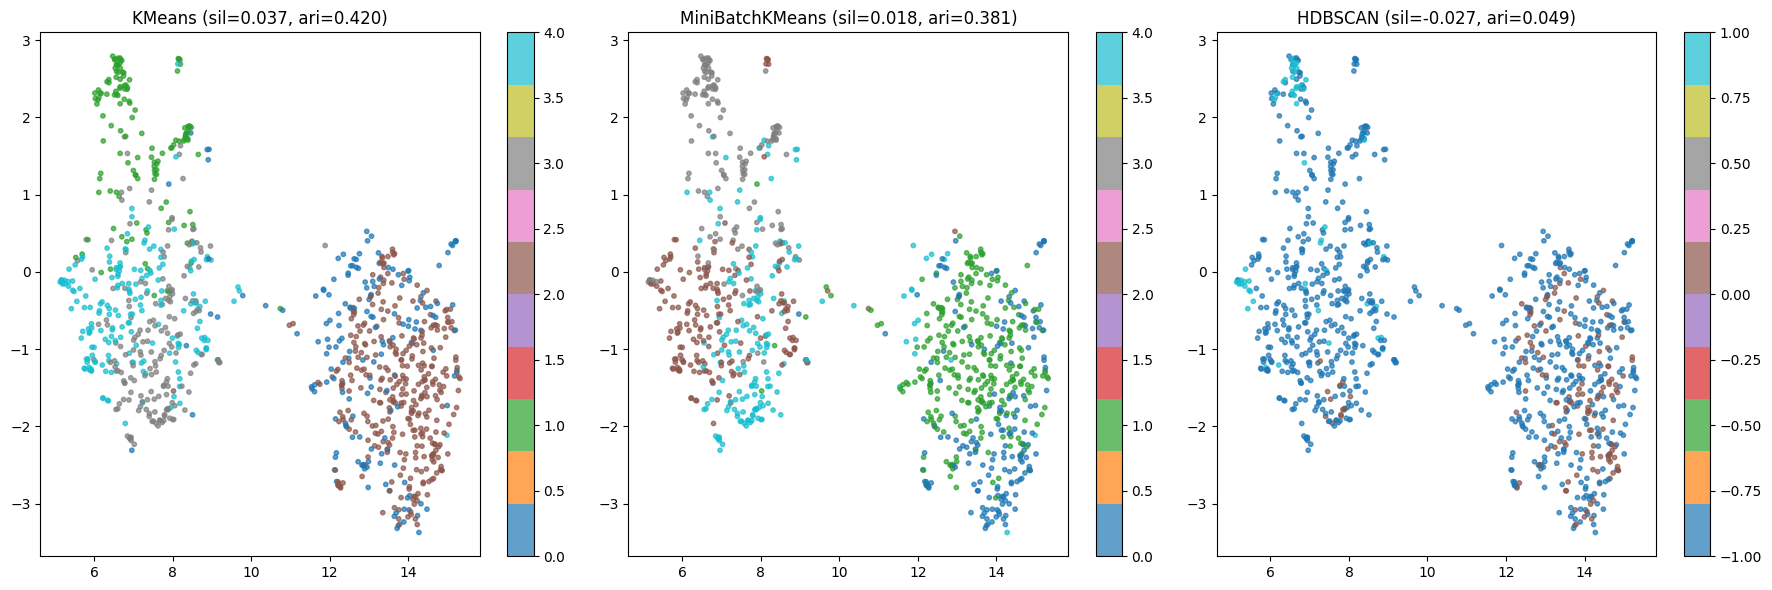

{'KMeans': {'silhouette': 0.036774199455976486, 'ari': 0.4204391082724831},
 'MiniBatchKMeans': {'silhouette': 0.018369456753134727,
  'ari': 0.3809938094204427},
 'HDBSCAN': {'silhouette': -0.027466872707009315, 'ari': 0.04862489104626613}}

In [12]:


true_labels = (cut_df["rating"] == 5.0).apply(int)
results = compare_clusterers(frida_embeds, true_labels=true_labels, n_clusters=5)
results

# Интерпретируемость кластеров

## BERTopic - 5 баллов

Попробуем построить интерпретацию получаемых кластеров с помощью BERTopic, реализованного в виде отдельного фреймворка (строит кластера, считает c-TF-IDF, отбирает самые частотные и характеризующие кластер слова).

Если считать частотные слова напрямую, то в топе окажется много служебные слов, которые называют "стоп-словами". Игнорируйте эти слова при построении BERTopic -- это можно сделать с помощью переопределения vectorizer_model, заменив его на sklearn.CountVectorizer с использованием nltk stopwords.

In [13]:
!pip install -q bertopic

In [14]:
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from nltk.corpus import stopwords
import nltk


from plotly.io import renderers
#renderers.default = "notebook_connected" # интерактив в Jupyter/Colab
try:
    stopwords.words('russian')
except:
    nltk.download('stopwords')
    stopwords.words('russian')
    
russian_stopwords = set(stopwords.words('russian'))
russian_stopwords.update([
    "это", "так", "вот", "как", "быть", "хороший", "плохой",
    "очень", "такой", "тот", "это", "тут", "там", "здесь"
])

vectorizer_model = CountVectorizer(stop_words=list(russian_stopwords))


In [15]:

# ---- Ваш код здесь ----
print("стоп-слова и векторайзер")
texts = cut_df["clean_text"].values


embedding_model = frida_model
topic_model = BERTopic(
    vectorizer_model=vectorizer_model,
    language="russian",
    calculate_probabilities=True,
    verbose=False,
    nr_topics=None,
    min_topic_size=10
)

# Обучение с pre-computed эмбеддингами
topics, probs = topic_model.fit_transform(texts, embeddings=frida_embeds)

#topics, probs = topic_model.fit_transform(texts)
# ---- Конец кода ----

стоп-слова и векторайзер



=== Топовые слова для каждого кластера ===

Кластер 0 (508 отзывов):
  Слова: вкусный, вкус, спасибо, рекомендую, средство, вкусные, просто, вкусная, нравится, качество

Кластер 1 (492 отзывов):
  Слова: вкус, запах, невозможно, пришлось, буду, просто, внутри, рекомендую, купила, фарш


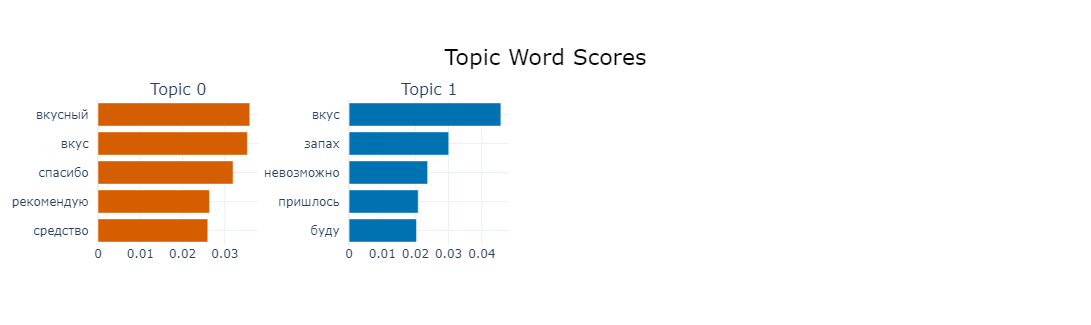

,text,topic
0,запекала сахар вместе с дыней. дыня совсем не ...,1
1,почти без запаха.,1
2,не понравились. начинки мало. к тому же в проц...,1
3,невозможно есть! очень невкусно,1
4,"недоквашенная она какая-то, много воды",1


In [16]:
print("\n=== Топовые слова для каждого кластера ===")
for topic_id in sorted(set(topics)):
    if topic_id == -1:
        print(f"\nАномалии (кластер -1): {sum(1 for t in topics if t == -1)} отзывов")
        continue
    
    topic_words = topic_model.get_topic(topic_id)
    if topic_words:
        words_str = ", ".join([word for word, _ in topic_words[:10]])
        topic_docs = [texts[i] for i, t in enumerate(topics) if t == topic_id]
        print(f"\nКластер {topic_id} ({len(topic_docs)} отзывов):")
        print(f"  Слова: {words_str}")

fig_bar = topic_model.visualize_barchart(top_n_topics=10)
fig_bar.show()


# 5. Датафрейм
df_topics = pd.DataFrame({
    'text': texts,
    'topic': topics
})
df_topics.head()

## Интерпретация через LLM - 15 баллов

Реализуйте интерпретацию кластеров с помощью LLM: кластеризуйте данные с помощью HDBSCAN, удалите аномалии (кластер -1), затем для каждого кластера насемплируйте 5-10 примеров.

Возьмите любую адекватную для русского языка LLM (например, saiga-yandexgpt из первой дз, либо для скорости можно взять qwen-2-0.5b -- хотя по качеству она будет достаточно слабой), и напишите к ней промпт, по которому данная ллм на основе семплированных отзывов должна написать короткое описание кластера.

В качестве результата выведите датафрейм, в котором для каждого кластера будет номер кластера, короткое описание кластера и использованный семпл.

In [17]:
# чистим cuda память
import gc

torch.cuda.empty_cache()
torch.cuda.empty_cache()
gc.collect()

46416

In [18]:
import pandas as pd
import numpy as np
import random
from sentence_transformers import SentenceTransformer
from sklearn.cluster import HDBSCAN
from sklearn.metrics.pairwise import cosine_distances
from openai import OpenAI

pd.set_option("display.max_colwidth", None)

# --- 1. Кластеризация HDBSCAN ---
print("Кластеризация HDBSCAN...")
hdbscan = HDBSCAN(min_cluster_size=50, min_samples=10, cluster_selection_epsilon=0.5)
hdbscan_labels = hdbscan.fit_predict(frida_embeds)

# Подсчет кластеров
unique_labels, counts = np.unique(hdbscan_labels, return_counts=True)
label_counts = dict(zip(unique_labels, counts))
print(f"Количество кластеров: {len([l for l in unique_labels if l >= 0])}")
print(f"Кластеры и их размеры: {label_counts}")

# --- 2. Удаление аномалий ---
mask_no_anomaly = hdbscan_labels != -1
texts_no_anomaly = np.array(texts)[mask_no_anomaly]
labels_no_anomaly = hdbscan_labels[mask_no_anomaly]
embeds_no_anomaly = frida_embeds[mask_no_anomaly]

print(f"После удаления аномалий: {len(texts_no_anomaly)} отзывов")

# --- 3. Семплирование примеров для каждого кластера ---
def sample_examples_for_cluster(texts, labels, cluster_id, n_samples=7):
    """Выбирает n_samples примеров из кластера"""
    cluster_mask = labels == cluster_id
    cluster_texts = texts[cluster_mask]
    
    if len(cluster_texts) <= n_samples:
        return list(cluster_texts)
    
    cluster_embeds = embeds_no_anomaly[cluster_mask]
    centroid = cluster_embeds.mean(axis=0).reshape(1, -1)
    distances = cosine_distances(cluster_embeds, centroid).flatten()
    
    sorted_indices = np.argsort(distances)
    
    middle_start = len(sorted_indices) // 4
    middle_end = 3 * len(sorted_indices) // 4
    middle_indices = sorted_indices[middle_start:middle_end]
    
    if len(middle_indices) < n_samples:
        middle_indices = sorted_indices[:n_samples]
    else:
        middle_indices = np.random.choice(middle_indices, size=n_samples, replace=False)
    
    sampled_texts = [cluster_texts[i] for i in middle_indices]
    return sampled_texts

# --- 4. Настройка OpenAI клиента для Ollama ---
client = OpenAI(base_url='http://192.168.1.3:11434/v1', api_key='ollama', )

model_name = "qwen3.5"  # Замените на нужную модель

# --- 5. Генерация описаний для всех кластеров ---
print("\nГенерация описаний кластеров...")

results = []
for cluster_id in sorted(set(labels_no_anomaly)):
    print(f"\nОбработка кластера {cluster_id}...")
    
    sampled = sample_examples_for_cluster(texts_no_anomaly, labels_no_anomaly, cluster_id, n_samples=7)
    
    # Формируем текст из отзывов
    texts_formatted = "\n".join([f"- {t[:300]}..." if len(t) > 300 else f"- {t}" for t in sampled])
    
    prompt = f"""Тебе предоставлены отзывы клиентов супермаркета "Перекрёсток". 
Кластеризуй их по смыслу и дай краткое описание проблемы/темы, объединяющей эти отзывы.

Отзывы:
{texts_formatted}

Ответь в формате: Краткое описание (1-2 предложения), без вводных слов.
"""
    
    # Вызов Ollama через OpenAI SDK
    try:
        completion = client.chat.completions.create(
            model=model_name,
            messages=[
                {"role": "system", "content": "Ты помощник для анализа отзывов клиентов."},
                {"role": "user", "content": prompt}
            ],
            temperature=0.3,
            max_tokens=150
        )
        description = completion.choices[0].message.content
    except Exception as e:
        description = f"Ошибка при вызове Ollama: {e}"
    
    results.append({
        'cluster_id': cluster_id,
        'description': description,
        'sample_count': len(sampled),
        'sample_texts': sampled
    })

# --- 6. Формирование датафрейма ---
df_results = pd.DataFrame(results)

df_results['sample_preview'] = df_results['sample_texts'].apply(
    lambda x: "; ".join([t[:100] + "..." if len(t) > 100 else t for t in x[:3]])
)

print("\n=== Результаты ===")
print(df_results[['cluster_id', 'description', 'sample_count']].to_string())
print("\n=== Полные данные ===")
df_results

Кластеризация HDBSCAN...
Количество кластеров: 2
Кластеры и их размеры: {np.int64(-1): np.int64(788), np.int64(0): np.int64(152), np.int64(1): np.int64(60)}
После удаления аномалий: 212 отзывов

Генерация описаний кластеров...

Обработка кластера 0...

Обработка кластера 1...

=== Результаты ===
   cluster_id                                                                                                                                                                                                                                                               description  sample_count
0           0  Низкое качество и несоответствие ожиданий по продуктам: обнаружены бракованные макароны, некачественная морковь (кормовая, безвкусная), испорченные или с неприятным привкусом и запахом готовые продукты (котлеты, консервы), а также продукты с неестественным цветом.             7
1           1                                                                    Отзывы объединены положительным оп

,cluster_id,description,sample_count,sample_texts,sample_preview
0,0,"Низкое качество и несоответствие ожиданий по продуктам: обнаружены бракованные макароны, некачественная морковь (кормовая, безвкусная), испорченные или с неприятным привкусом и запахом готовые продукты (котлеты, консервы), а также продукты с неестественным цветом.",7,"[макароны крошатся. варим по инструкции, причём не одну пачку. не советую покупать их, морковь привезли кормовую! размером 30 см, парки какие-то а не морковь. сок из нее совсем не сладкий, а практически безвкусный. не рекомендую!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!, невозможно есть! очень невкусно, неестественно желтый, со странным неприятным привкусом. больше брать не буду., не понравилась, солёная, даже не доели банку. есть с чем сравнить, брала другую, больше экспериментировать не буду..., при готовке сильный запах (хряка). аппетита не вызывает. больше покупать не планируем, самые ужасные котлеты, которые я когда либо ел. кажется, даже котлеты из бумаги вкуснее этого. не рекомендую.]","макароны крошатся. варим по инструкции, причём не одну пачку. не советую покупать их; морковь привезли кормовую! размером 30 см, парки какие-то а не морковь. сок из нее совсем не сладкий...; невозможно есть! очень невкусно"
1,1,"Отзывы объединены положительным опытом использования продуктов и товаров бренда «Помидорка» и чистящих средств: клиенты хвалят их за натуральный состав, вкус, эффективность и удобство использования.",7,"[всей семьей очень любим всю линейку товаров "" помидорка""! очень сочно и вкусно!а главное - состав соответствует цене. действительно 100% натуральный продукт., очень вкусная томатная паста, без всяких консервантов. в составе помидоры. всегда беру только ее, вкусный горошек, советую!, отличное молоко, с натуральным вкусом. и киснет как надо! если остается, делаю дочке творожок., лучшее чистящее средство для сантехники. отчищает любую грязь и приятно пахнет. пользуемся этим средством с момента появления его в продаже. рекомендую всем, кто хочет чистоты!, томатную пасту использую не часто, но если беру, то только помидорку. очень нравится вкус. и баночка такая маленькая удобно-использовал и никаких проблем., единственное средство которое защищает санузел и уделяет все загрязнения, не оставляя подтеков и каких либо следов) всем советую)]","всей семьей очень любим всю линейку товаров "" помидорка""! очень сочно и вкусно!а главное - состав со...; очень вкусная томатная паста, без всяких консервантов. в составе помидоры. всегда беру только ее; вкусный горошек, советую!"


# snorkel / flyingsquid - 10 баллов

В данном разделе предлагается воспользоваться фреймворком для semi-supervised кластеризации, в котором можно определить lf-функции, отображающие некоторые эвристики, и использовать их для автоматической доразметки данных. Необходимо написать как минимум 9 новых правдоподобных правил (то есть суммарно должно быть 10).

В качестве альтернативы допускается использовать flyingsquid (чуть устаревший вариант) -- шаблон кода под него расположен ниже

Для лучшего понимания интерфейса и функциональности предлагается ознакомиться с документацией фреймворков в сети.

In [24]:
import numpy as np
import pandas as pd
from snorkel.labeling import labeling_function, PandasLFApplier
from snorkel.labeling.model import LabelModel

# --- 1. Подготовка данных ---
texts = cut_df["clean_text"].values
df = pd.DataFrame({"text": texts})

# Константы для меток
ABSTAIN = -1
DELIVERY = 0
QUALITY = 1
SERVICE = 2
PRICE = 3

# --- 2. Labeling функции (без скобок у декоратора) ---
@labeling_function()
def lf_has_delivery_keywords(series):
    return DELIVERY if any(w in series.text.lower() for w in ["доставка", "курьер", "привезли", "опоздал", "вовремя"]) else ABSTAIN
# 9 дополнительных LF:
@labeling_function()
def lf_has_quality_better(series):
    return QUALITY if any(w in series.text.lower() for w in ["хорош", "отличн", "качеств", "свеж", "вкусн"]) else ABSTAIN
@labeling_function()
def lf_has_quality_worse(series):
    return QUALITY if any(w in series.text.lower() for w in ["плох", "испорчен", "гнил", "вял", "неразм"]) else ABSTAIN
@labeling_function()
def lf_has_service_praise(series):
    return SERVICE if any(w in series.text.lower() for w in ["Operators", "менеджер", "консультант", "помощ", "вежлив", "профессиональ"]) else ABSTAIN
@labeling_function()
def lf_has_service_complaint(series):
    return SERVICE if any(w in series.text.lower() for w in ["груб", "некорректн", "неприятн", "медленн", "неотвеча"]) else ABSTAIN
@labeling_function()
def lf_has_price_expensive(series):
    return PRICE if any(w in series.text.lower() for w in ["дорог", "переплат", "неприличн", "зашкалив"]) else ABSTAIN
@labeling_function()
def lf_has_price_affordable(series):
    return PRICE if any(w in series.text.lower() for w in ["дешев", "выгодн", "акци", "распродаж", "низк цена"]) else ABSTAIN
@labeling_function()
def lf_has_delivery_praise(series):
    return DELIVERY if any(w in series.text.lower() for w in ["быстр", "своевременн", "упакован", "цел", "аккуратн"]) else ABSTAIN
@labeling_function()
def lf_has_delivery_complaint(series):
    return DELIVERY if any(w in series.text.lower() for w in ["разбит", "мокр", "грязн", "не тот", "отсутств"]) else ABSTAIN
@labeling_function()
def lf_has_positive_emotion(series):
    return QUALITY if any(w in series.text.lower() for w in ["спасиб", " bueno", "отлично", "супер", "замечательн"]) else ABSTAIN
@labeling_function()
def lf_has_negative_emotion(series):
    return QUALITY if any(w in series.text.lower() for w in ["беспощадн", "ужасн", "никудышн", "не рекомендую", "отвратительн"]) else ABSTAIN

# --- 3. Применение labeling функций ---
lfs = [
    lf_has_delivery_keywords,
    lf_has_quality_better, lf_has_quality_worse,
    lf_has_service_praise, lf_has_service_complaint,
    lf_has_price_expensive, lf_has_price_affordable,
    lf_has_delivery_praise, lf_has_delivery_complaint,
    lf_has_positive_emotion, lf_has_negative_emotion
]


applier = PandasLFApplier(lfs)
L = applier.apply(df)

print(f"Матрица labeling функций: {L.shape}")

# --- 4. Обучение LabelModel ---
label_model = LabelModel(cardinality=4, verbose=False)
label_model.fit(L_train=L, n_epochs=500, log_freq=50, seed=42)

# --- 5. Предсказания ---
Y_pred = label_model.predict(L=L)

# --- 6. Анализ результатов ---
print("\n=== Распределение предсказанных меток ===")
unique, counts = np.unique(Y_pred, return_counts=True)
label_names = ["DELIVERY", "QUALITY", "SERVICE", "PRICE"]
for label, count in zip(unique, counts):
    print(f"{label_names[label]}: {count} ({count/len(Y_pred)*100:.2f}%)")

# --- 7. Добавление в датафрейм ---
df["predicted_label"] = Y_pred
df["label_name"] = df["predicted_label"].map(lambda x: label_names[x])

# --- 8. Вывод примеров ---
print("\n=== Примеры для каждой метки ===")
for label in range(4):
    label_examples = df[df["predicted_label"] == label]["text"].head(3)
    print(f"\n{label_names[label]}:")
    for i, example in enumerate(label_examples):
        print(f"  {i+1}. {example[:150]}...")

print("\n=== Датафрейм с результатами ===")
df[["text", "predicted_label", "label_name"]].head(20)

100%|█████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2929.57it/s]


Матрица labeling функций: (1000, 11)


100%|████████████████████████████████████████████████████████████████████████████| 500/500 [00:00<00:00, 2116.25epoch/s]


=== Распределение предсказанных меток ===
PRICE: 422 (42.20%)
DELIVERY: 91 (9.10%)
QUALITY: 434 (43.40%)
SERVICE: 50 (5.00%)
PRICE: 3 (0.30%)

=== Примеры для каждой метки ===

DELIVERY:
  1. самые ужасные котлеты, которые я когда либо ел. кажется, даже котлеты из бумаги вкуснее этого. не рекомендую....
  2. не рекомендую. совершенно не вкусная, жесткая, какая-то искусственная икра. открыла и выбросила....
  3. отвратительный творог! резиновый, безвкусный. в пакете 700 грамм, думала, что не закончится никогда. когда осталось грамм 200, решила сделать сырники....

QUALITY:
  1. не понравились. начинки мало. к тому же в процессе варки все вареники "раскрылись" как цветочки , начинка вытекла. есть пустое тесто невкусно....
  2. невозможно есть! очень невкусно...
  3. масло очень низкого качества, максимум на жарку использовать. дома закончилось масло, в очередной заезд в магазин решила попробовать, польстившись на ...

SERVICE:
  1. запекала сахар вместе с дыней. дыня совсем не пропеклас

,text,predicted_label,label_name
0,запекала сахар вместе с дыней. дыня совсем не пропеклась по причине плохой свертываемости сахара. вывод: сахар недостаточно уварен,2,SERVICE
1,почти без запаха.,-1,PRICE
2,"не понравились. начинки мало. к тому же в процессе варки все вареники ""раскрылись"" как цветочки , начинка вытекла. есть пустое тесто невкусно.",1,QUALITY
3,невозможно есть! очень невкусно,1,QUALITY
4,"недоквашенная она какая-то, много воды",-1,PRICE
5,недоквашенная,-1,PRICE
6,"покупала 2-е банки в декабре-вчера открыли одну-тухлая!когда открывала,то крышка чуть вспухла,но я так надеялась,что хорошая,но нет.судьбу 2-ой банки не знаю,т.к. её мы подарили на нг.очень неприятно.",2,SERVICE
7,"самые ужасные котлеты, которые я когда либо ел. кажется, даже котлеты из бумаги вкуснее этого. не рекомендую.",0,DELIVERY
8,"масло очень низкого качества, максимум на жарку использовать. дома закончилось масло, в очередной заезд в магазин решила попробовать, польстившись на цену, но бесплатный сыр... в общем, лучше доплатить и купить сразу хорошее.",1,QUALITY
9,резиновый творог,-1,PRICE
